In [2]:
import pandas as pd,matplotlib.pyplot as plt,seaborn as sns

In [3]:
data = pd.read_csv('spam.csv',encoding='latin-1')

In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   v1          5572 non-null   str  
 1   v2          5572 non-null   str  
 2   Unnamed: 2  50 non-null     str  
 3   Unnamed: 3  12 non-null     str  
 4   Unnamed: 4  6 non-null      str  
dtypes: str(5)
memory usage: 217.8 KB


In [5]:
data.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [6]:
data.columns 

Index(['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], dtype='str')

In [7]:
data.drop(['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'],axis=1,inplace=True)

In [8]:
data.rename(columns={'v1':'result','v2':'text'},inplace=True)

In [9]:
data.head()

,result,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [10]:
import spacy
nlp = spacy.load('en_core_web_sm')

In [11]:
def extract(texts):
    DataFrame = []
    for ix,doc in enumerate(list(nlp.pipe(texts))):
        for token in doc:
            DataFrame.append({'token':token.text,'tag':token.pos_,'label':token.ent_type_})
    return pd.DataFrame(DataFrame)

In [12]:
spam = extract(data[data.result=='spam']['text'])
ham  = extract(data[data.result=='ham']['text'])

In [13]:
spam.head()

,token,tag,label
0,Free,ADJ,
1,entry,NOUN,
2,in,ADP,
3,2,NUM,CARDINAL
4,a,DET,


In [14]:
ham.head()

,token,tag,label
0,Go,VERB,
1,until,ADP,
2,jurong,PROPN,
3,point,PROPN,
4,",",PUNCT,


In [15]:
spam_counts = spam.groupby(['token','tag']).size().reset_index(name='counts').sort_values(by='counts',ascending=False)

In [16]:
spam_counts.head()

,token,tag,counts
50,.,PUNCT,986
0,!,PUNCT,507
38,",",PUNCT,369
3800,to,ADP,361
2422,a,DET,358


In [17]:
spam.groupby(['tag'])['token'].count().sort_values(ascending=False)

tag
NOUN     3903
PROPN    3351
PUNCT    2563
VERB     2327
NUM      1890
ADP      1408
ADJ      1173
PRON     1117
DET       772
AUX       664
ADV       574
CCONJ     466
PART      429
SYM       229
INTJ      132
SCONJ     126
X         107
Name: token, dtype: int64

In [18]:
ham_counts = ham.groupby(['token','tag']).size().reset_index(name='counts').sort_values(by='counts',ascending=False)

In [19]:
ham_counts.head()

,token,tag,counts
76,.,PUNCT,3903
1524,I,PRON,1942
10825,you,PRON,1690
53,",",PUNCT,1488
374,?,PUNCT,1307


In [20]:
ham.groupby(['tag'])['token'].count().sort_values(ascending=False)

tag
NOUN     11991
PRON     11040
VERB     11030
PUNCT    10940
PROPN     5876
AUX       5403
ADP       4980
ADV       4442
ADJ       3766
DET       3193
PART      2320
CCONJ     2026
SCONJ     1680
INTJ      1671
NUM       1203
SPACE      449
X          233
SYM         59
Name: token, dtype: int64

[Text(0.5, 1.0, 'Common Tags in Spam News')]

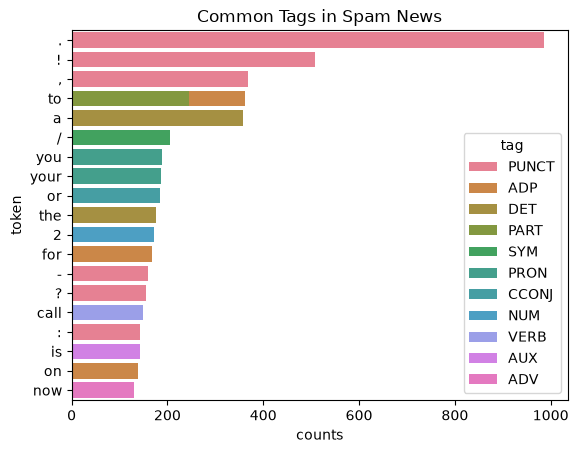

In [21]:
sns.barplot(
    x = 'counts',
    y = 'token',
    hue = 'tag',
    data = spam_counts[:20],
    orient='h',
    dodge = False
).set(title='Common Tags in Spam News')

[Text(0.5, 1.0, 'Common Tags in Ham News')]

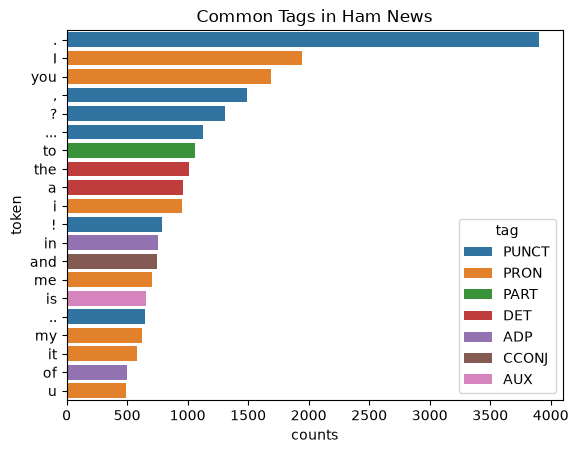

In [22]:
sns.barplot(
    x = 'counts',
    y = 'token',
    hue = 'tag',
    data = ham_counts[:20],
    orient='h',
    dodge=False
).set(title='Common Tags in Ham News')

In [23]:
spam_ents = spam[spam.label!=''].groupby(['token','label']).size().reset_index(name='counts').sort_values(by='counts',ascending=False)

In [24]:
ham_ents = ham[ham.label!=''].groupby(['token','label']).size().reset_index(name='counts').sort_values(by='counts',ascending=False)

In [25]:
spam_ents.head()

,token,label,counts
289,2,CARDINAL,147
407,4,CARDINAL,84
816,FREE,ORG,68
1500,week,DATE,45
3,&,ORG,45


In [26]:
ham_ents

,token,label,counts
81,2,CARDINAL,254
152,4,CARDINAL,119
1709,today,DATE,104
1234,day,DATE,91
11,&,ORG,86
...,...,...,...
719,MY,PRODUCT,1
718,MR,ORG,1
717,MOST,ORG,1
716,MOON,ORG,1


[Text(0.5, 1.0, 'Common labels in Spam News !')]

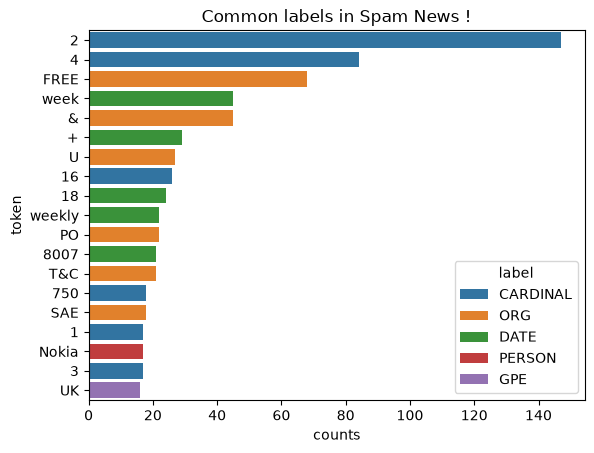

In [27]:
sns.barplot(
    x = 'counts',
    y = 'token',
    hue = 'label',
    data = spam_ents[:20],
    orient = 'h',
    dodge = False
).set(title='Common labels in Spam News !')

[Text(0.5, 1.0, 'Common labels in Ham News !')]

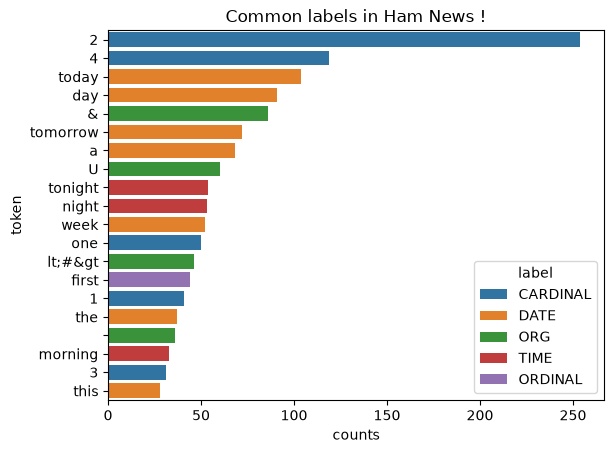

In [28]:
sns.barplot(
    x = 'counts',
    y = 'token',
    hue = 'label',
    data = ham_ents[:20],
    orient = 'h',
    dodge = False
).set(title='Common labels in Ham News !')

In [29]:
import nltk,re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

In [30]:
data['text_clean'] = data['text'].str.lower().apply(lambda x : re.sub(r'^[^-]*-\s*','',x))
data['text_clean'] = data['text_clean'].apply(lambda x :re.sub(r'[^\w\s]','',x))

In [31]:
stopwords = stopwords.words('english')

In [32]:
data['text_clean'] = data['text_clean'].apply(lambda x : ' '.join([word for word in x.split() if word not in stopwords]))

In [33]:
data['text_clean'] = data['text_clean'].apply(lambda x:word_tokenize(x))

In [34]:
lemmatizer = WordNetLemmatizer()

In [35]:
data['text_clean'] = data['text_clean'].apply(lambda tokens : [lemmatizer.lemmatize(token) for token in tokens])

In [36]:
data.head()

,result,text,text_clean
0,ham,"Go until jurong point, crazy.. Available only ...","[go, jurong, point, crazy, available, bugis, n..."
1,ham,Ok lar... Joking wif u oni...,"[ok, lar, joking, wif, u, oni]"
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,"[free, entry, 2, wkly, comp, win, fa, cup, fin..."
3,ham,U dun say so early hor... U c already then say...,"[u, dun, say, early, hor, u, c, already, say]"
4,ham,"Nah I don't think he goes to usf, he lives aro...","[nah, dont, think, go, usf, life, around, though]"


In [37]:
tokens = sum(data['text_clean'],[])

In [38]:
unigrams = pd.Series(nltk.ngrams(tokens,1)).value_counts()

<Axes: >

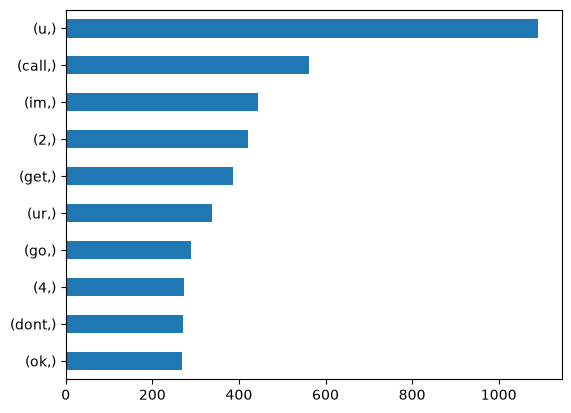

In [39]:
unigrams[:10].sort_values(ascending=True).plot.barh()

<Axes: >

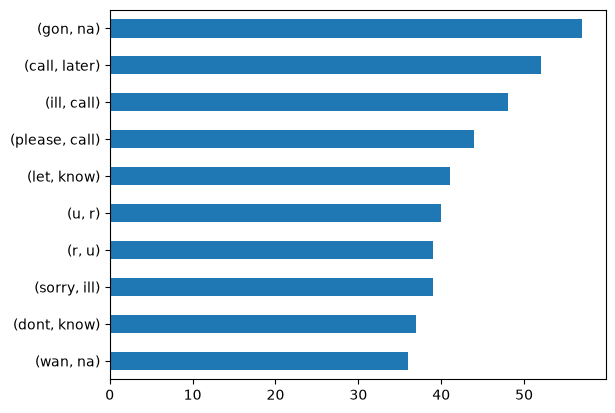

In [40]:
bigrams = pd.Series(nltk.ngrams(tokens,2)).value_counts()
bigrams[:10].sort_values(ascending=True).plot.barh()

In [41]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

In [42]:
analyzer = SentimentIntensityAnalyzer()

In [43]:
data['sentiment'] = data['text'].apply(lambda x : analyzer.polarity_scores(x)['compound'])

In [44]:
data['labels'] = pd.cut(data['sentiment'],bins=[-1,-0.1,0.1,1],labels=['negative','neutral','positive'])

In [45]:
data.head()

,result,text,text_clean,sentiment,labels
0,ham,"Go until jurong point, crazy.. Available only ...","[go, jurong, point, crazy, available, bugis, n...",0.4019,positive
1,ham,Ok lar... Joking wif u oni...,"[ok, lar, joking, wif, u, oni]",0.4767,positive
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,"[free, entry, 2, wkly, comp, win, fa, cup, fin...",0.7964,positive
3,ham,U dun say so early hor... U c already then say...,"[u, dun, say, early, hor, u, c, already, say]",0.0000,neutral
4,ham,"Nah I don't think he goes to usf, he lives aro...","[nah, dont, think, go, usf, life, around, though]",-0.1027,negative


<Axes: xlabel='labels', ylabel='count'>

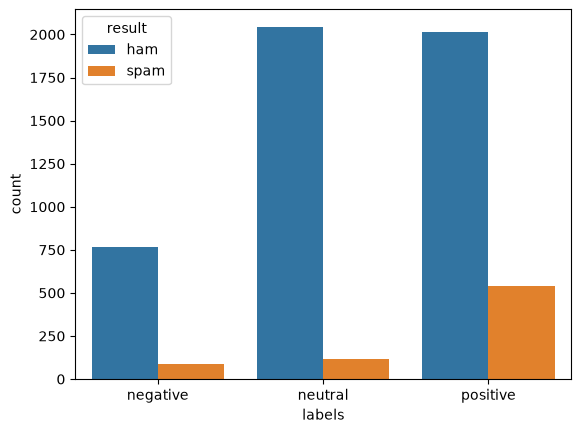

In [46]:
sns.countplot(
    x = data['labels'],
    hue = data['result'],
)

<Axes: xlabel='result', ylabel='count'>

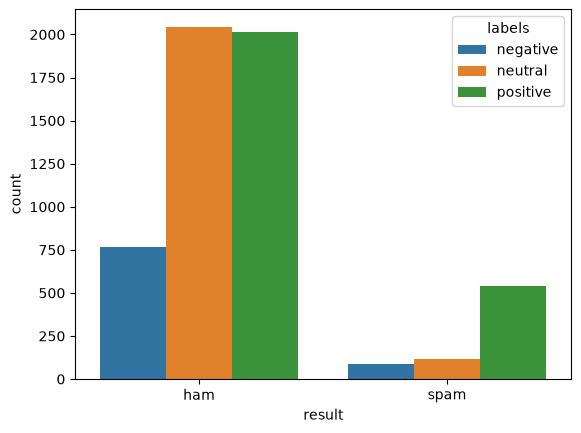

In [47]:
sns.countplot(
    x = data['result'],
    hue = data['labels']
)

In [48]:
import gensim
from gensim import corpora
from gensim.models import LsiModel,TfidfModel
from gensim.models.coherencemodel import CoherenceModel

In [49]:
coherence_scores = []
model_list = []
min_topics = 2
max_topics = 10

In [50]:
spam_texts = data[data.result=='spam']['text_clean'].reset_index(drop=True)
dictionary = corpora.Dictionary(spam_texts)
corpus = [dictionary.doc2bow(text) for text in spam_texts]

In [51]:
for i in range(min_topics,max_topics+1):
    model = gensim.models.LdaModel(corpus,id2word=dictionary,num_topics=i)
    model_list.append(model)
    cmodel = CoherenceModel(model,dictionary=dictionary,texts=spam_texts,coherence='c_v')
    coherence_scores.append(cmodel.get_coherence())

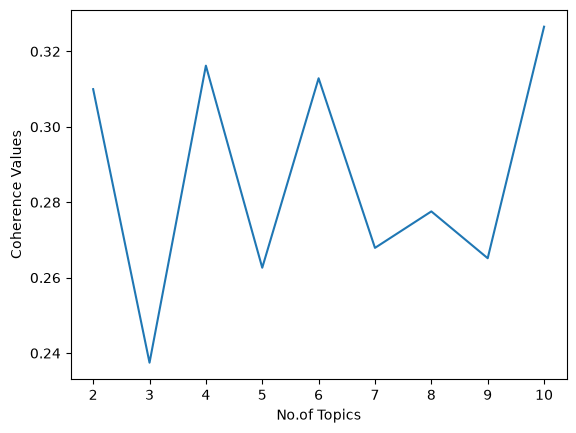

In [52]:
plt.plot(range(min_topics,max_topics+1),coherence_scores)
plt.xlabel('No.of Topics')
plt.ylabel('Coherence Values')
plt.show()

In [53]:
lda = gensim.models.LdaModel(corpus,id2word=dictionary,num_topics=5)
lda.print_topics(num_topics=5,num_words=5)

[(0, '0.029*"call" + 0.016*"txt" + 0.014*"free" + 0.013*"claim" + 0.012*"u"'),
 (1, '0.019*"ur" + 0.016*"call" + 0.015*"free" + 0.015*"2" + 0.015*"txt"'),
 (2,
  '0.033*"call" + 0.025*"free" + 0.015*"mobile" + 0.013*"text" + 0.012*"stop"'),
 (3, '0.015*"4" + 0.015*"call" + 0.011*"free" + 0.010*"cash" + 0.009*"2"'),
 (4, '0.020*"call" + 0.015*"mobile" + 0.014*"2" + 0.011*"reply" + 0.010*"u"')]

In [54]:
from sklearn.linear_model import LogisticRegression,SGDClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,classification_report
from sklearn.feature_extraction.text import TfidfVectorizer,CountVectorizer

In [55]:
X = [','.join(map(str,l)) for l in data['text_clean']]
y = data['result']

In [56]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [57]:
tfidf = TfidfVectorizer()

In [58]:
X_trainVec = tfidf.fit_transform(X_train)
X_testvec = tfidf.transform(X_test)

In [59]:
lr = LogisticRegression().fit(X_trainVec,y_train)

In [60]:
predction = lr.predict(X_testvec)

In [61]:
accuracy_score(predction,y_test)

0.9497757847533632

In [62]:
print(classification_report(y_test,predction))

              precision    recall  f1-score   support

         ham       0.95      1.00      0.97       965
        spam       0.96      0.65      0.78       150

    accuracy                           0.95      1115
   macro avg       0.95      0.82      0.87      1115
weighted avg       0.95      0.95      0.95      1115



In [63]:
svm = SGDClassifier().fit(X_trainVec,y_train)

In [64]:
ysvm = svm.predict(X_testvec)

In [65]:
accuracy_score(y_test,ysvm)

0.9802690582959641

In [66]:
print(classification_report(ysvm,y_test))

              precision    recall  f1-score   support

         ham       1.00      0.98      0.99       985
        spam       0.86      0.99      0.92       130

    accuracy                           0.98      1115
   macro avg       0.93      0.99      0.96      1115
weighted avg       0.98      0.98      0.98      1115



In [67]:
def checkSpam(message):
    vec = tfidf.transform(message)
    result = svm.predict(vec)
    print('*'*90)
    print(message)
    print('*'*90)
    print(result)

In [68]:
checkSpam(['Hurray ! get a chance win a free Iphone by registering to our website '])

******************************************************************************************
['Hurray ! get a chance win a free Iphone by registering to our website ']
******************************************************************************************
['spam']


In [69]:
checkSpam(['it is raining here i will be late to the office todday !'])

******************************************************************************************
['it is raining here i will be late to the office todday !']
******************************************************************************************
['ham']
